# Bike Sharing Demand Prediction

#### Objective
* Predict the hourly count of rental bikes in a bike-sharing system based on temporal, weather, and seasonal features. 
* This is a regression problem with time series elements.

In [39]:
# importation 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 


In [40]:
df = pd.read_csv('day.csv')
df.head(10)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
5,6,2011-01-06,1,0,1,0,4,1,1,0.204348,0.233209,0.518261,0.089565,88,1518,1606
6,7,2011-01-07,1,0,1,0,5,1,2,0.196522,0.208839,0.498696,0.168726,148,1362,1510
7,8,2011-01-08,1,0,1,0,6,0,2,0.165000,0.162254,0.535833,0.266804,68,891,959
8,9,2011-01-09,1,0,1,0,0,0,1,0.138333,0.116175,0.434167,0.361950,54,768,822
9,10,2011-01-10,1,0,1,0,1,1,1,0.150833,0.150888,0.482917,0.223267,41,1280,1321


## EDA

## Features explainations :
instant: record index

dteday: date (YYYY-MM-DD)

season: season (1:spring, 2:summer, 3:fall, 4:winter)

yr: year (0: 2011, 1: 2012)

mnth: month (1 to 12)

holiday: whether day is holiday or not

weekday: day of the week

workingday: if day is neither weekend nor holiday

weathersit: weather situation (1:clear, 2:mist, 3:light rain/snow, 4:heavy rain)

temp: normalized temperature in Celsius (feature, not target!)

atemp: normalized "feels like" temperature

hum: normalized humidity

windspeed: normalized wind speed

casual: count of casual users

registered: count of registered users

#### Analyse de Forme :
* identify target  => is the columns 'cnt' = total rental count
* num of ligne & colonne  =>  ligne=731, colonne=16
* type des variables(features)  => all numerical (int - float)
* identifiant Nan (missing values)  => no Nan Yay 
  
+ elimine some columns that arent important like:

#### Analyse de Forme :
* Visualisation de target  => majority of target value btw (3000-6000)
*  Comprehension des diff var (seperatly)  => 
*   Visualisation des relations entre features with target and with each others  => 
*   Identification des outliers  => just in 3 Features (holiday:21 - windspeed:13 - hum:2)

## Conclusion (Comprehension des diff var) & (isualisation des relations entre features)
#### feature visualisation
* season :we can tell there almost the same of repetation of season
  
* instant: not important (gonna be elimante)

* dteday: all have the same forme (yy-mm-day) (better to elimine since we have already column for month and year(binary) and day

* mnth: majority of data is in btw month(5-10)

* holiday: (0:not holiday) more frenquent than (1:holiday) normal workday is more than holiday

* weekday(day of week): frequent the same for all day

* workingday (0:not workday , 1;workday) is the opposite of holiday//workday(1) more than notworkday(0)

* weathersit (1:clear, 2:mist, 3:light rain/snow, 4:heavy rain):most is (1:clear) after that (2:mist) lastly(3:light rain/snow)

* temp:temputer go btw range(0.1 to 0.9)

* atemp: temputer alike go btw range(0.1 to 0.9)

* hum: humidity go btw range(0.2 to 1) - and the most frenquent in (0,5 - 0,8)

* windspeed: go btw range(0.2 to 1) - and the most frenquent in (1,5 - 0,2)

* casual(count Number of one-time users who rented a bike):the count of users btw (450 - 1000) (gonna be elimante = data leakage)

* registered(Number of members/subscribers who rented a bike):go btw (2500-4000) (gonna be elimante = data leakage)

* cnt: number of bikes rented (cnt = casual + registered)

#### relation btw features with each other 
* temp - weathersit: temp go btw (0.3-0.7)in clear weather(1) ,temp go btw (0.3-0.6)in misty weather(2) and temp go btw (0.4-0.6)in light rainy/snow weather(1)
* atemp - weathersit:same as temp (in clear weather atemp is higher echelle) and (in light rain/snow is least eachelle)
* hum - weathersit:humide is higher in light rainy/snow and least humide in clear day
* windspeed - weathersit:windspeed is higher in light rainy/snowy weather and lower and the same in misty and clear weather

#### realation btw features n target 
*  season :the most season that the rent bike is higher in fall,next spring ,summer and lastly is winter
  
*  yr : year 2012(1) is more hourly rent compaire to 2011(0)
  
*  mnth: majority of data is in btw month(5-10) have the heighly hours of rent (make sence is in fall and spring)
  
*  holiday: num of bike rent is more in worday(since it most frequent)then holiday but not that big diffrent btw the 2 (mean in holiday people have free time more to rent bike for long time )
  
*  weekday(day of week): almost identical the num of rent bike in each day yet its most in day 4 n 5 after that 3 n 6 and it comes the other days
  
*  workingday:hours of bike rent is more in worday(most frequent)then not workday however not that big diffrent btw the 2 (mean in holiday people have free time more to rent bike for long time
  
* weathersit: we see the heigly num rent of bike in clear weather(1) and lastly in light rain/snow(3) noraml
  
* casual- registered (cnt = casual + registered) => data leackage
  
* big relation cnt and (instant- atemp - temp- yr -season -mnth)

big relation btw cnt and (instant- atemp - temp- yr -season -mnth)

<Figure size 1200x1000 with 0 Axes>

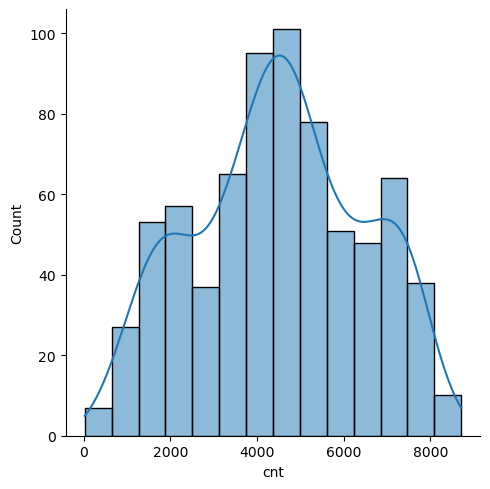

In [41]:
plt.figure(figsize=(12,10))
sns.displot(df['cnt'], kde=True)

In [42]:
df.shape

(731, 16)

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [44]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

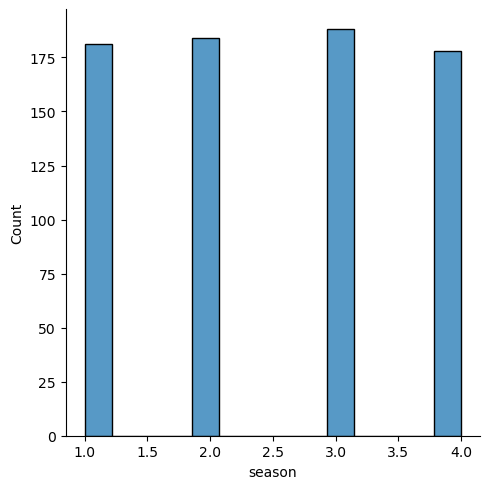

In [45]:
#season
sns.displot(x='season', data=df)
plt.show() # we can tell there almost the same of repetation of season 

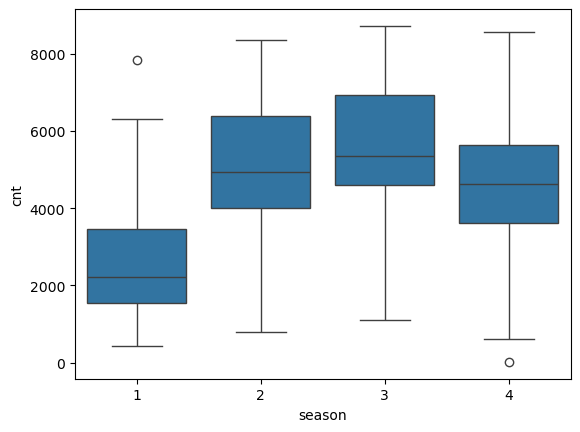

In [46]:
sns.boxplot(x='season', y='cnt', data=df)
plt.show()

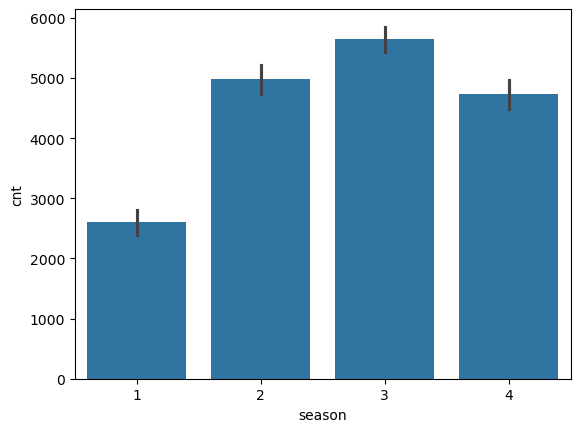

In [47]:
sns.barplot(x='season', y='cnt', data=df, estimator=np.mean)
plt.show() # the most seson that the rent hours is higher in fall,next spring ,summer and lastly is winter 

In [48]:
df['dteday'].unique # all have the same forme (yy-mm-day)

<bound method Series.unique of 0      2011-01-01
1      2011-01-02
2      2011-01-03
3      2011-01-04
4      2011-01-05
          ...    
726    2012-12-27
727    2012-12-28
728    2012-12-29
729    2012-12-30
730    2012-12-31
Name: dteday, Length: 731, dtype: object>

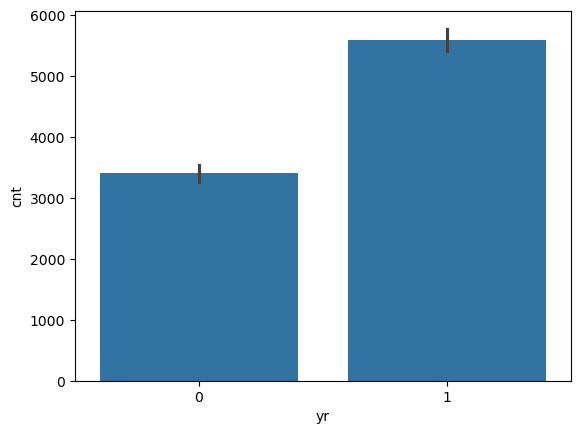

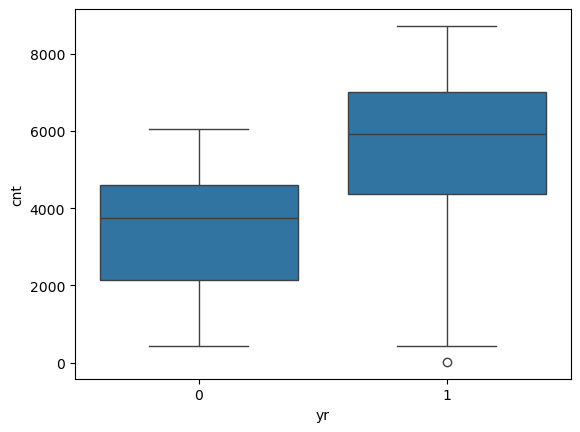

In [49]:
# year
sns.barplot(x='yr',y='cnt' ,data=df)
plt.show()  #the year 2012(1) is more hourly rent compaire to 2011(0)

sns.boxplot(x='yr',y='cnt' ,data=df)
plt.show() 

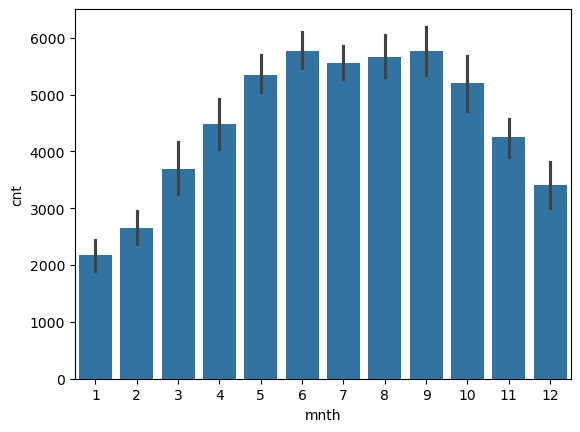

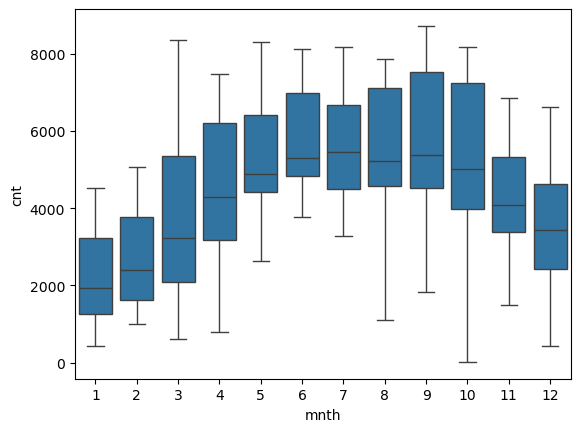

In [50]:
#mont
sns.barplot(x='mnth',y='cnt',data=df)
plt.show()

sns.boxplot(x='mnth',y='cnt',data=df)
plt.show()

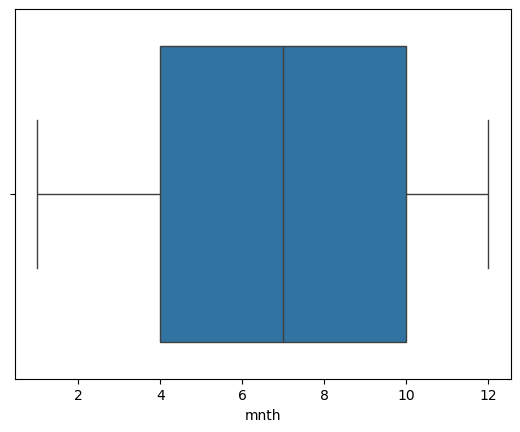

In [51]:
sns.boxplot(x='mnth',data=df)
plt.show() 

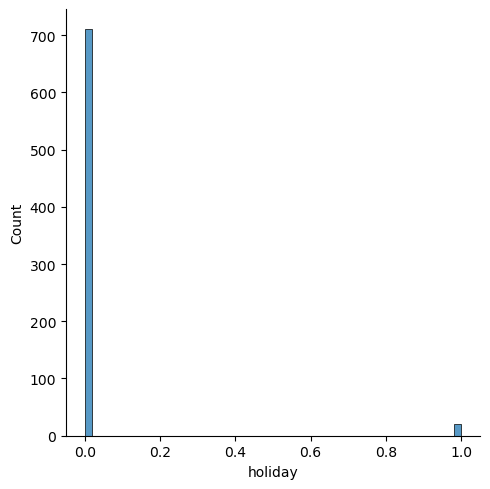

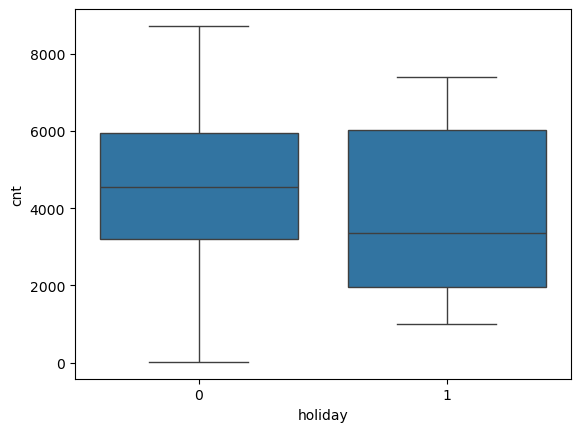

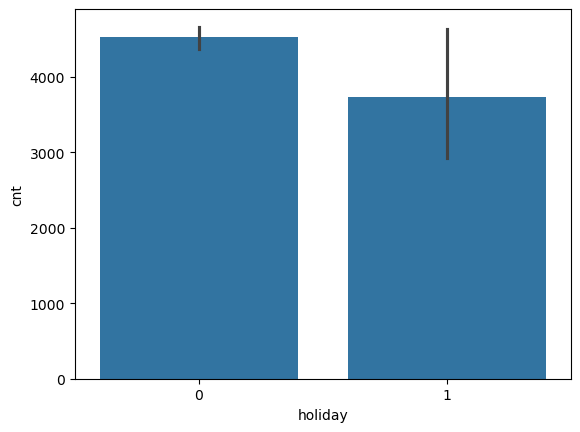

In [52]:
# holiday
sns.displot(x='holiday',data=df)
plt.show() # normal workday is more than holiday

sns.boxplot(x='holiday',y='cnt',data=df)
plt.show() 

sns.barplot(x='holiday',y='cnt',data=df)
plt.show() 
# hours of bike rent is more in worday(since it most frequent)then holiday but not that big diffrent btw the 2 (mean in holiday people have free time more to rent bike for long time )

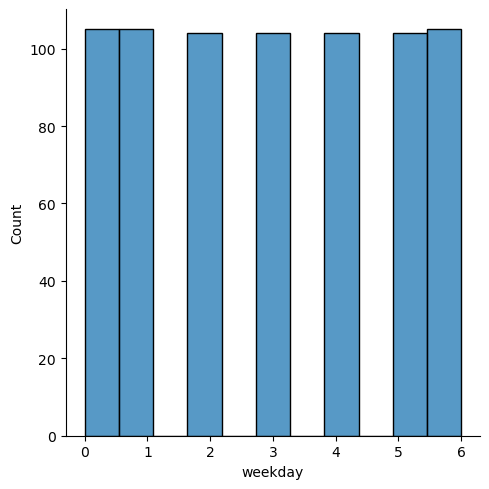

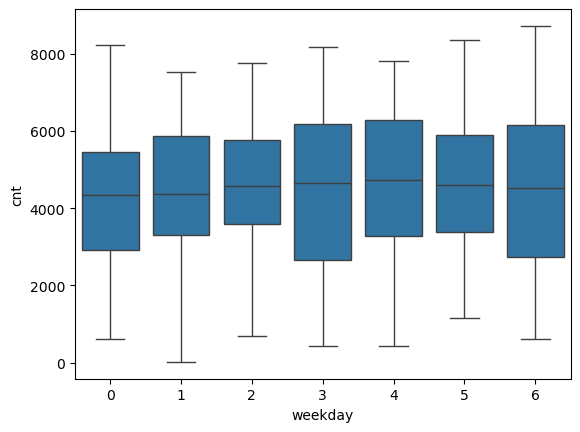

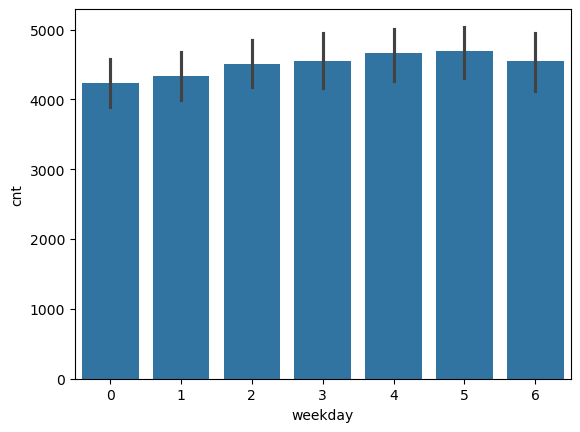

In [53]:
# weekday(day of week)
sns.displot(x='weekday',data=df)
plt.show() #frequent the same 

sns.boxplot(x='weekday',y='cnt',data=df)
plt.show() 

sns.barplot(x='weekday',y='cnt',data=df)
plt.show()
# weekday: almost identical the hours of rent bike in each day yet its most in day 4 n 5 after that 3 n 6 and it comes the other days

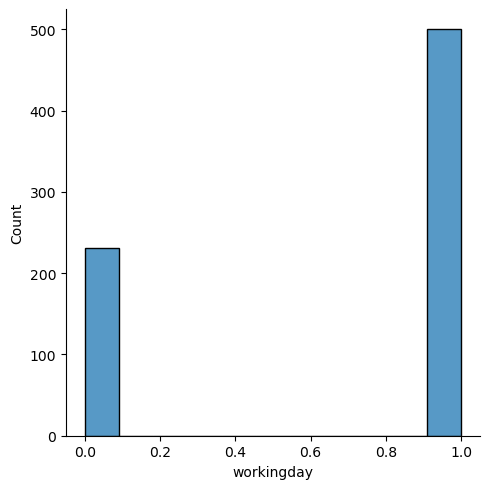

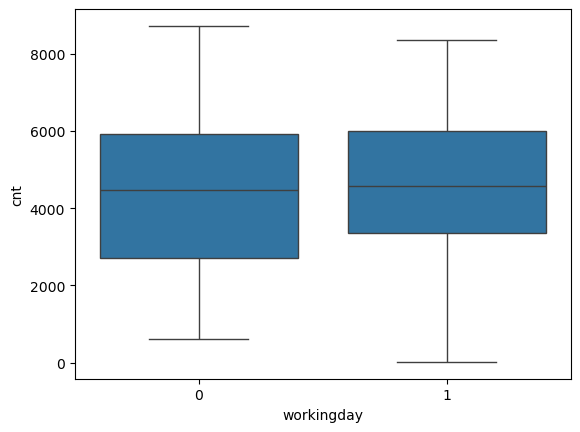

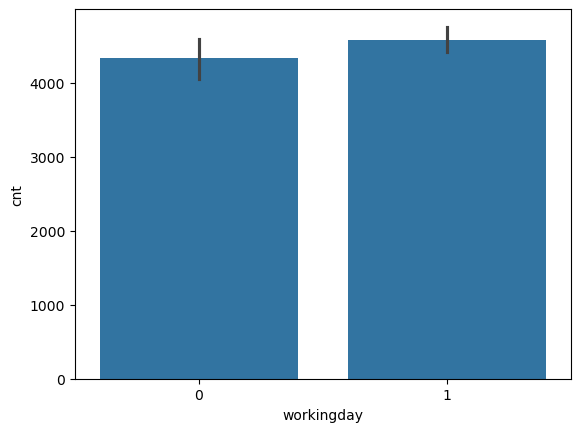

In [54]:
# workingday (0:not workday , 1;workday) is the opposite of holiday
sns.displot(x='workingday',data=df)
plt.show() # workday(1) more than notworkday(0)

sns.boxplot(x='workingday',y='cnt',data=df)
plt.show() 

sns.barplot(x='workingday',y='cnt',data=df)
plt.show()
# workingday:hours of bike rent is more in worday(most frequent)then not workday however not that big diffrent btw the 2 (mean in holiday people have free time more to rent bike for long time 

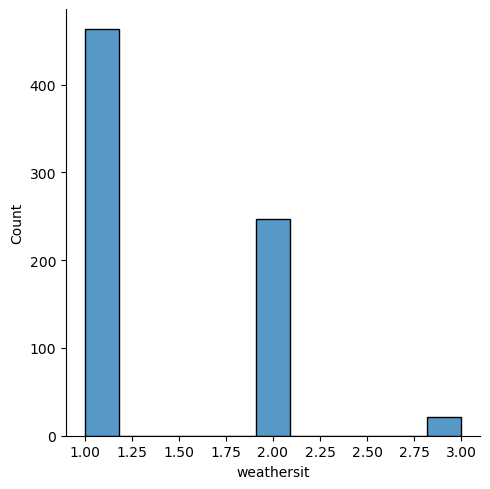

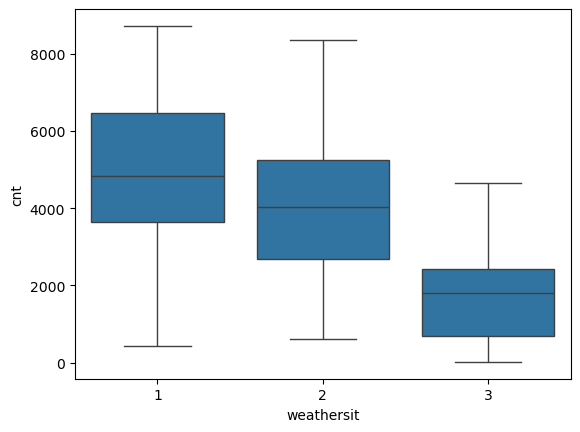

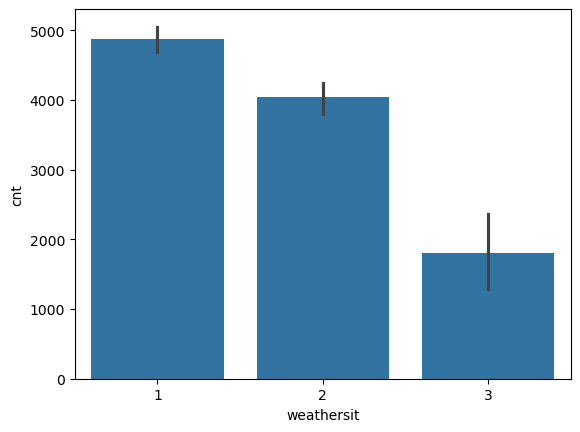

In [55]:
# weathersit: weather situation (1:clear, 2:mist, 3:light rain/snow, 4:heavy rain)
sns.displot(x='weathersit',data=df)
plt.show() # weathersit:most is (1:clear) after that (2:mist) lastly(3:light rain/snow)

sns.boxplot(x='weathersit',y='cnt',data=df)
plt.show() 

sns.barplot(x='weathersit',y='cnt',data=df)
plt.show()# we see the heigly hours rent of bike in clear weather(1) and lastly in light rain/snow(3) noraml

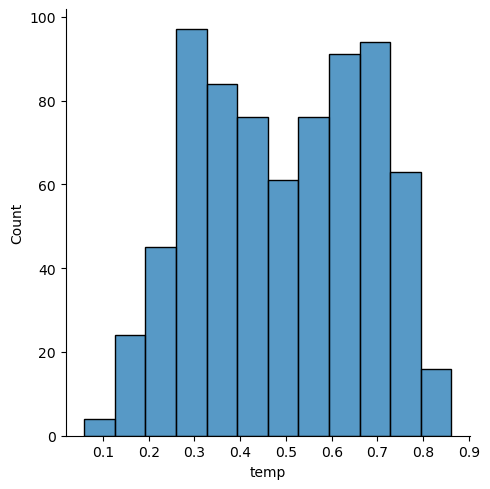

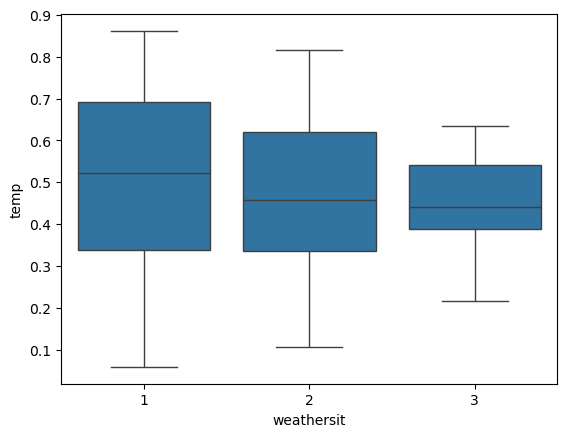

<function matplotlib.pyplot.show(close=None, block=None)>

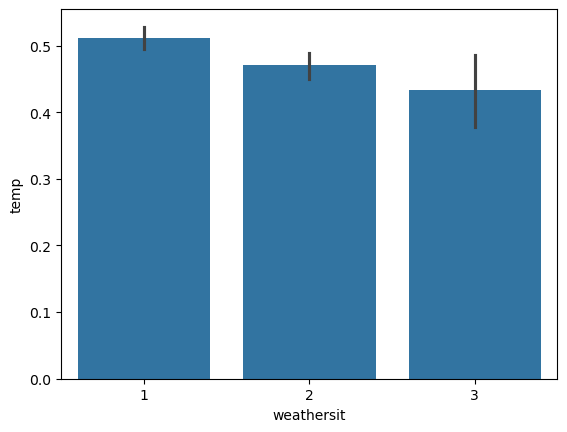

In [56]:
#temp
sns.displot(x='temp',data=df)
plt.show() # temputer go btw range(0.1 to 0.9)

#temp with weather sitution 
sns.boxplot(x='weathersit',y='temp',data=df)
plt.show() 

sns.barplot(x='weathersit',y='temp',data=df)
plt.show #temp go btw (0.3-0.7)in clear weather(1) ,temp go btw (0.3-0.6)in misty weather(2) and temp go btw (0.4-0.6)in light rainy/snow weather(1)

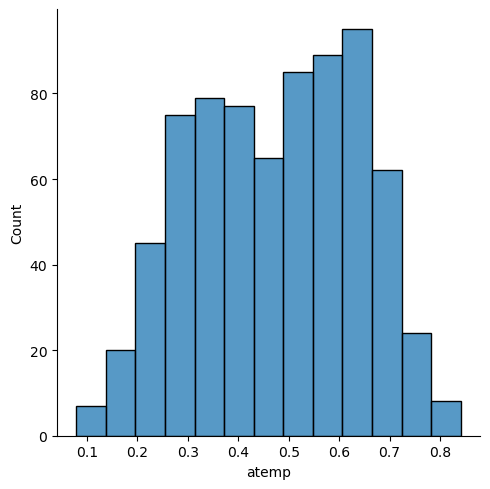

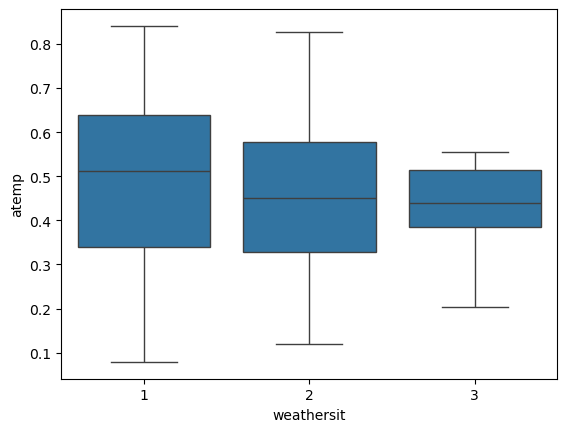

<function matplotlib.pyplot.show(close=None, block=None)>

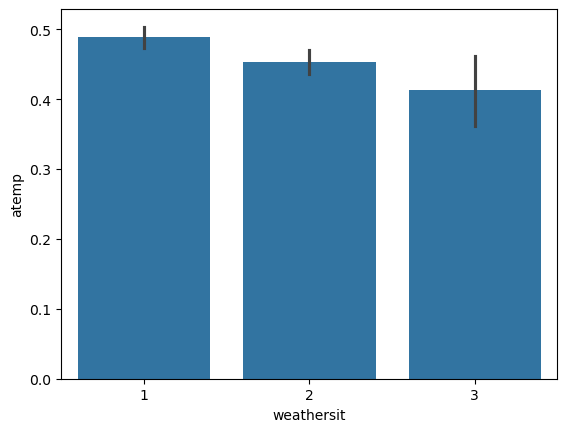

In [57]:
#atemp
sns.displot(x='atemp',data=df)
plt.show() # temputer alike go btw range(0.1 to 0.9)

#atemp with weather sitution 
sns.boxplot(x='weathersit',y='atemp',data=df)
plt.show() 

sns.barplot(x='weathersit',y='atemp',data=df)
plt.show  #same as temp (in clear weather atemp is higher echelle) and (in light rain/snow is least eachelle)


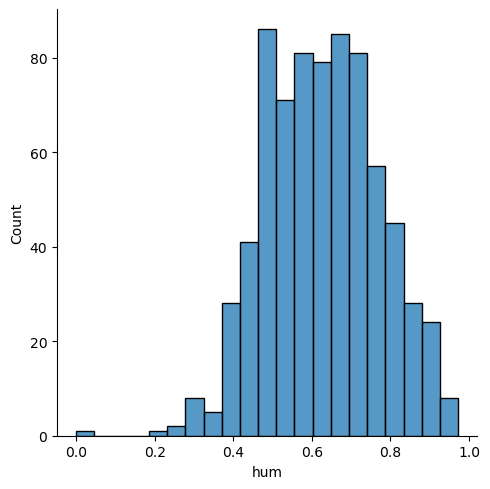

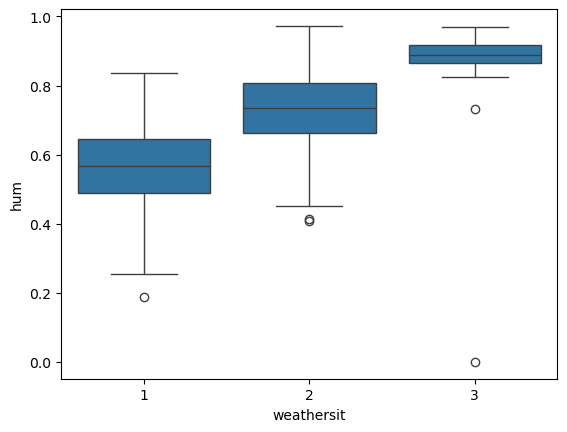

<function matplotlib.pyplot.show(close=None, block=None)>

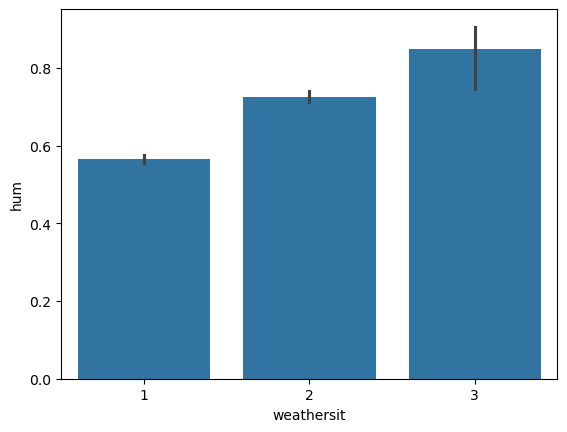

In [58]:
#hum
sns.displot(x='hum',data=df)
plt.show() # humidity go btw range(0.2 to 1) - and the most frenquent in (0,5 - 0,8)

#hum with weather sitution 
sns.boxplot(x='weathersit',y='hum',data=df)
plt.show() 

sns.barplot(x='weathersit',y='hum',data=df)
plt.show  # humide is higher in light rainy/snow and least humide in clear day


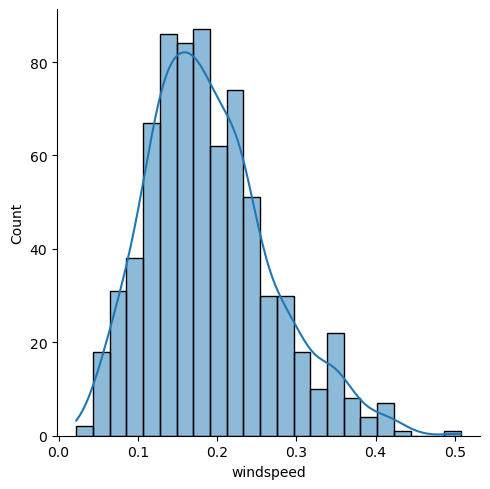

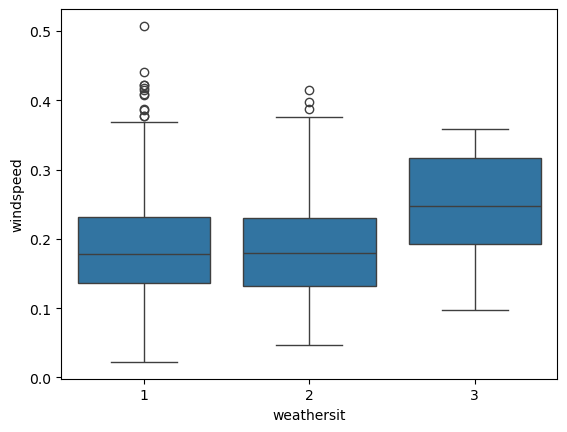

<function matplotlib.pyplot.show(close=None, block=None)>

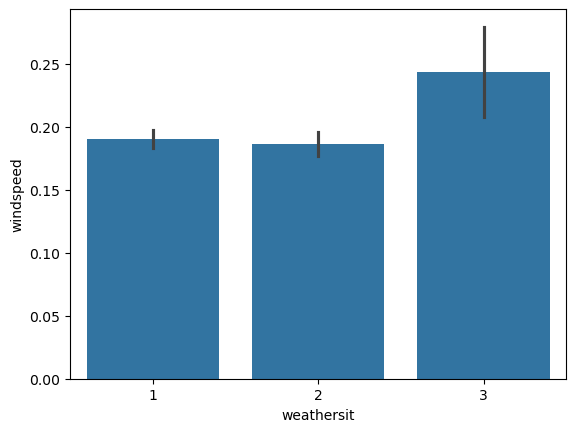

In [59]:
#windspeed
sns.displot(x='windspeed',kde=True,data=df)
plt.show() # windspeed go btw range(0.2 to 1) - and the most frenquent in (1,5 - 0,2)

#windspeed with weather sitution 
sns.boxplot(x='weathersit',y='windspeed',data=df)
plt.show()  #windspeed is higher in light rainy/snowy weather and lower and the same in misty and clear weather

sns.barplot(x='weathersit',y='windspeed',data=df)
plt.show

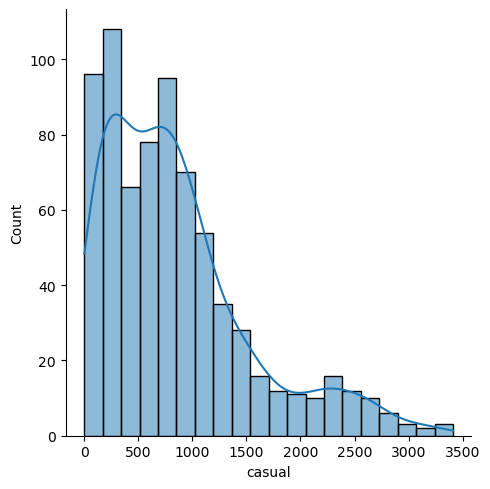

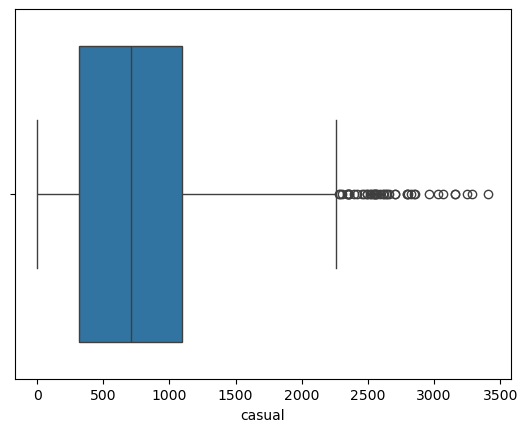

In [60]:
#casual(count of casual users) - Non-registered users (tourists, one-time users)

sns.displot(x='casual',data=df, kde=True)
plt.show() 

sns.boxplot(x='casual',data=df)
plt.show()  # the count of users btw (450 - 1000)

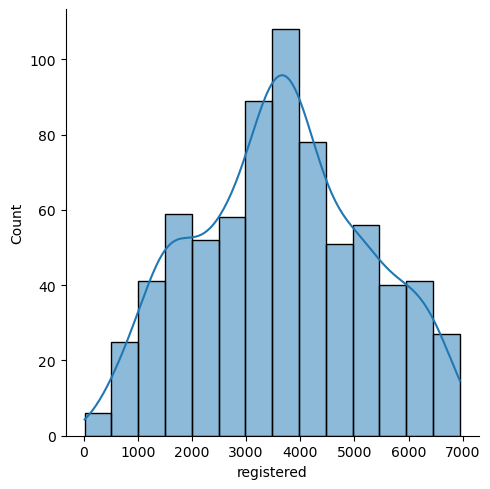

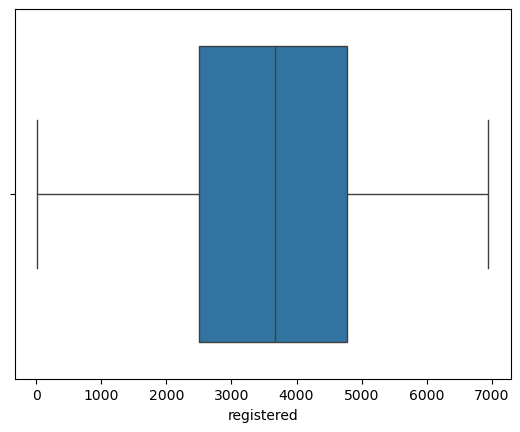

In [61]:
#registered (num of sub/member who rent bike) go btw (2500-4000)
sns.displot(x='registered',data=df, kde=True)
plt.show() 

sns.boxplot(x='registered',data=df)
plt.show()

In [62]:
df = df.drop(['dteday','holiday'],axis=1)

In [63]:
print(df.columns)
print(df.shape)

Index(['instant', 'season', 'yr', 'mnth', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt'],
      dtype='object')
(731, 14)


In [64]:
df.head(10)

,instant,season,yr,mnth,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,1,0,1,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,1,0,1,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,1,0,1,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,1,0,1,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,1,0,1,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
5,6,1,0,1,4,1,1,0.204348,0.233209,0.518261,0.089565,88,1518,1606
6,7,1,0,1,5,1,2,0.196522,0.208839,0.498696,0.168726,148,1362,1510
7,8,1,0,1,6,0,2,0.165000,0.162254,0.535833,0.266804,68,891,959
8,9,1,0,1,0,0,1,0.138333,0.116175,0.434167,0.361950,54,768,822
9,10,1,0,1,1,1,1,0.150833,0.150888,0.482917,0.223267,41,1280,1321


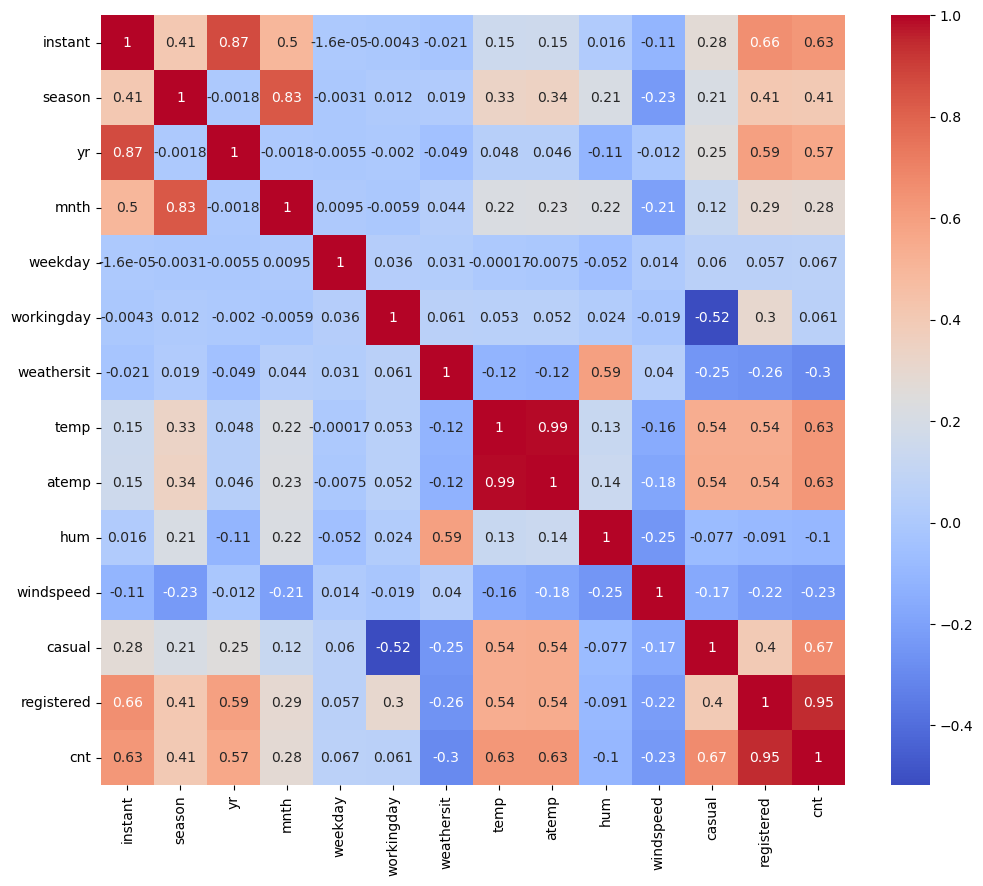

In [65]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr() , annot=True , cmap='coolwarm')
plt.show()

In [66]:
matrice_correlation = df.corr()
matrice_correlation # big relation cnt and (instant- atemp - temp- yr -season -mnth)

,instant,season,yr,mnth,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
instant,1.000000,0.412224,0.866025,0.496702,-0.000016,-0.004337,-0.021477,0.150580,0.152638,0.016375,-0.112620,0.275255,0.659623,0.628830
season,0.412224,1.000000,-0.001844,0.831440,-0.003080,0.012485,0.019211,0.334315,0.342876,0.205445,-0.229046,0.210399,0.411623,0.406100
yr,0.866025,-0.001844,1.000000,-0.001792,-0.005461,-0.002013,-0.048727,0.047604,0.046106,-0.110651,-0.011817,0.248546,0.594248,0.566710
mnth,0.496702,0.831440,-0.001792,1.000000,0.009509,-0.005901,0.043528,0.220205,0.227459,0.222204,-0.207502,0.123006,0.293488,0.279977
weekday,-0.000016,-0.003080,-0.005461,0.009509,1.000000,0.035790,0.031087,-0.000170,-0.007537,-0.052232,0.014282,0.059923,0.057367,0.067443
workingday,-0.004337,0.012485,-0.002013,-0.005901,0.035790,1.000000,0.061200,0.052660,0.052182,0.024327,-0.018796,-0.518044,0.303907,0.061156
weathersit,-0.021477,0.019211,-0.048727,0.043528,0.031087,0.061200,1.000000,-0.120602,-0.121583,0.591045,0.039511,-0.247353,-0.260388,-0.297391
temp,0.150580,0.334315,0.047604,0.220205,-0.000170,0.052660,-0.120602,1.000000,0.991702,0.126963,-0.157944,0.543285,0.540012,0.627494
atemp,0.152638,0.342876,0.046106,0.227459,-0.007537,0.052182,-0.121583,0.991702,1.000000,0.139988,-0.183643,0.543864,0.544192,0.631066
hum,0.016375,0.205445,-0.110651,0.222204,-0.052232,0.024327,0.591045,0.126963,0.139988,1.000000,-0.248489,-0.077008,-0.091089,-0.100659


In [67]:
# Separate numeric and categorical columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

# --- Detect outliers using IQR method ---
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    print(f"{col}: {len(outliers)} outliers")

instant: 0 outliers
season: 0 outliers
yr: 0 outliers
mnth: 0 outliers
weekday: 0 outliers
workingday: 0 outliers
weathersit: 0 outliers
temp: 0 outliers
atemp: 0 outliers
hum: 2 outliers
windspeed: 13 outliers
casual: 44 outliers
registered: 0 outliers
cnt: 0 outliers


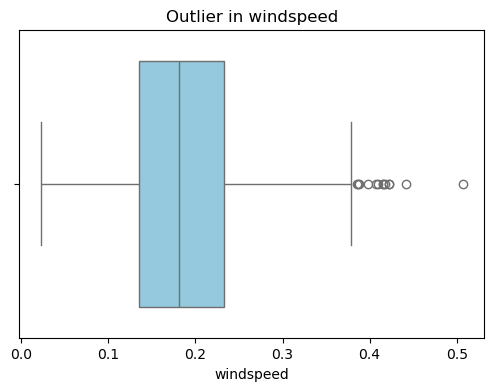

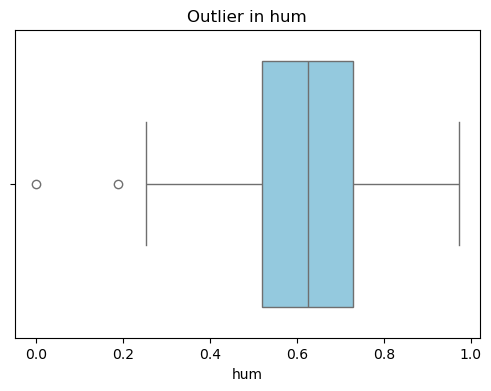

In [69]:

# --- Detect outliers in columns that have outliers  using boxplots ---

#windspeed
plt.figure(figsize=(6,4))
sns.boxplot(x=df['windspeed'], color="skyblue")
plt.title("Outlier in windspeed")
plt.show()


#hum 
plt.figure(figsize=(6,4))
sns.boxplot(x=df['hum'], color="skyblue")
plt.title("Outlier in hum")
plt.show()

# Pre-processing

is the process of getting our dataset ready for model training. In this section, we will perform the following preprocessing steps:

* Data cleaning (lignes(duplicate/non pertinetes)- colonne(redandance/donnees incorrect/nan/outliers)
* Drop and fill missing values (no used)
* Encoding (no used)
* Data trasformation (log transformation) - suppression outliers
* Feature engineering
* Features Scaling
* Create Train Test set

In [ ]:
df.columns

In [70]:
df.head()

,instant,season,yr,mnth,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,1,0,1,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,1,0,1,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,1,0,1,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,1,0,1,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,1,0,1,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [71]:
duplicate_lignes = df.duplicated()
duplicate_lignes # no duplicated lignes 

0      False
1      False
2      False
3      False
4      False
       ...  
726    False
727    False
728    False
729    False
730    False
Length: 731, dtype: bool

In [72]:
df.isnull().sum() # no nan

instant       0
season        0
yr            0
mnth          0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

#### train test set split

In [73]:
from sklearn.model_selection import train_test_split

In [77]:
x = df.drop(['cnt','casual','registered'],axis=1) #drop 'casual','registered' to avoid data leakage 
y = df['cnt']

x_train , x_test , y_train , y_test = train_test_split(x,y, test_size=0.25 , random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(548, 11)
(183, 11)
(548,)
(183,)


#### feature scalling (make it in same echelle)
* Normalization (Min-Max) =>This rescales values into a fixed range, usually [0,1].
* Standardization (Z-score Scaling)=>This rescales values so that each feature has mean = 0 and standard deviation = 1.


how to choose :
* If your features have different ranges but are bounded, use Normalization.

* If your features have different distributions or unbounded values, use Standardization.

* If unsure, start with Standardization — it’s more robust in practice.

In [78]:
df.describe()

,instant,season,yr,mnth,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [79]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_sc = scaler.fit_transform(x_train)

x_test= scaler.transform(x_test)

## Modelling 

In [134]:
# model 1 : regression linear 

In [135]:
from sklearn.linear_model import LinearRegression

In [136]:
lr = LinearRegression() #build model 
lr.fit(x_train_sc,y_train) # train model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [137]:
y_train_pred_lr = lr.predict(x_train_sc)
y_test_pred_lr = lr.predict(x_test)

In [138]:
from sklearn.metrics import r2_score , mean_absolute_error

In [139]:
r2_score_train_lr = r2_score(y_train,y_train_pred_lr) #78%
r2_score_test_lr = r2_score(y_test,y_test_pred_lr) #81%

mean_absolute_error_train_lr = mean_absolute_error(y_train,y_train_pred_lr)
mean_absolute_error_test_lr = mean_absolute_error(y_test,y_test_pred_lr)

print('r2_score_train_lr',r2_score_train_lr)
print('r2_score_test_lr',r2_score_test_lr)
print('mean_absolute_error_train_lr',mean_absolute_error_train_lr)
print('mean_absolute_error_test_lr',mean_absolute_error_test_lr)
# not bad score since its the 1st model (train score= 78% n test score= 81%)

r2_score_train_lr 0.7884334654727851
r2_score_test_lr 0.8151064398196682
mean_absolute_error_train_lr 652.3777306022563
mean_absolute_error_test_lr 610.44416013969


In [140]:
# model 2:Lasso Regression

In [141]:
from sklearn.linear_model import Lasso

In [142]:
lasso = Lasso(alpha=0.1, random_state=42, max_iter=10000) #build model 
lasso.fit(x_train_sc,y_train) # train model

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [143]:
y_pred_lasso = lasso.predict(x_test)

In [158]:
mae = mean_absolute_error(y_test,y_pred_lasso)
print('mean_absolute_error',mae)
r2_lasso = r2_score(y_test,y_pred_lasso)
print('r2_lasso_score',r2_lasso)  
# give 81%

mean_absolute_error 610.3283844385837
r2_lasso_score 0.8155882145149871


In [159]:
# model 3 : descion tree 

In [160]:
from sklearn.tree import DecisionTreeRegressor

In [161]:
DTR= DecisionTreeRegressor(random_state=42)
DTR.fit(x_train_sc,y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_l

In [162]:
y_train_pred_svr = svr.predict(x_train_sc)
y_test_pred_svr  = svr.predict(x_test)

In [163]:
y_pred = DTR.predict(x_test)

In [164]:
mae = mean_absolute_error(y_test,y_pred)
print('mean_absolute_error',mae)
r2_dtr = r2_score(y_test,y_pred)
print('r2_dtr_score',r2_dtr)
# score 78%

mean_absolute_error 617.1912568306011
r2_dtr_score 0.7891086576219424


In [165]:
# model 4 : XGBRegressor

In [166]:
from xgboost import XGBRegressor

In [167]:
XGB = XGBRegressor(
    objective='reg:squarederror',
    learning_rate=0.01,
    max_depth=6,
    n_estimators=1000,
    subsample=0.65,
    random_state=42
)# parameter of model is descion tree
XGB.fit(x_train_sc,y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [168]:
y_pred_xgb = XGB.predict(x_test)

In [169]:
mae = mean_absolute_error(y_test,y_pred_xgb)
print('mean_absolute_error',mae)
r2_xgb = r2_score(y_test,y_pred_xgb)
print('r2_xgb',r2_xgb)  
# much much much better with 90% yay :)

mean_absolute_error 380.8721008300781
r2_xgb 0.9062429070472717


In [170]:
# model 5: MLPRegressor (Multi-Layer Perceptron)

In [171]:
from sklearn.neural_network import MLPRegressor

In [172]:
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),  # Two hidden layers: 64 and 32 neurons
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42
)

mlp.fit(x_train_sc, y_train)

y_pred_mlp = mlp.predict(x_test)

C:\Users\hp\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [173]:
print("Mean Squared Error:", mean_absolute_error(y_test, y_pred_mlp))
print("R² Score:", r2_score(y_test, y_pred_mlp)) # score of 60%

Mean Squared Error: 830.4356553653249
R² Score: 0.6642362662523137


In [174]:
print('r2_score_test_lr',r2_score_test_lr) 
print('r2_lasso_score',r2) 
print('r2_dtr_score',r2_dtr)
print('r2_xgb',r2_xgb)  
print('r2_mlp',r2_score(y_test, y_pred_mlp))

r2_score_test_lr 0.8151064398196682
r2_lasso_score 0.8155882145149871
r2_dtr_score 0.7891086576219424
r2_xgb 0.9062429070472717
r2_mlp 0.6642362662523137


# # Conclusion :Performance Summary

We evaluated several regression models on the Bike Sharing Demand dataset.  
The performance was measured using **R² score** on the test set:

- **Linear Regression (R² = 0.8151)**  
  Strong baseline model. Captures linear trends but limited for complex relationships.

- **Lasso Regression (R² = 0.8156)**  
  Similar to Linear Regression with slight improvement. Regularization helps reduce overfitting and feature redundancy.

- **Decision Tree Regressor (R² = 0.7891)**  
  Lower performance compared to linear models. Single trees tend to overfit; better used in ensembles.

- **XGBoost (R² = 0.9062)**  
  Best performing model. Handles non-linearities and feature interactions effectively. Recommended as the primary model.

- **MLP Regressor (R² = 0.6642)**  
  Weakest result. Neural networks require more tuning and larger datasets. Not ideal for this problem without optimization.

### Key Takeaways
- **XGBoost** is the most accurate model and should be prioritized for deployment.  
- **Linear/Lasso Regression** serve as good interpretable baselines.  
- **Decision Tree** is weaker alone but useful inside ensembles.  
- **MLP** underperformed and is not recommended unless further optimized.


In [175]:
# Done 